# Using Analyzers
For this first example, we loaded a pre-trained LeNet5 model
to look at feature attributions on the MNIST dataset.

Note that most of the methods in the Julia-XAI ecosystem are **not** limited to Flux.jl models.

In [1]:
using ExplainableAI
using RelevancePropagation
using Zygote
using Flux

using BSON # hide
model = BSON.load("../model.bson", @__MODULE__)[:model] # load pre-trained LeNet-5 model

Chain(
  Conv((5, 5), 1 => 6, relu),           # 156 parameters
  MaxPool((2, 2)),
  Conv((5, 5), 6 => 16, relu),          # 2_416 parameters
  MaxPool((2, 2)),
  Flux.flatten,
  Dense(256 => 120, relu),              # 30_840 parameters
  Dense(120 => 84, relu),               # 10_164 parameters
  Dense(84 => 10),                      # 850 parameters
)                   # Total: 10 arrays, 44_426 parameters, 174.359 KiB.

## Preparing the input data
We use MLDatasets to load a single image from the MNIST dataset:

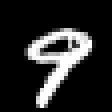

In [2]:
using MLDatasets
using ImageCore, ImageIO, ImageShow

index = 10
x, y = MNIST(Float32, :test)[10]

convert2image(MNIST, x)

By convention in Flux.jl, this input needs to be resized to WHCN format
by adding a color channel and batch dimensions.

In [3]:
input = reshape(x, 28, 28, 1, :);

## Feature attributions
We can now select an analyzer of our choice and call `analyze`
to get an `Attribution`. Here, we use the `LRP` method from
[RelevancePropagation.jl](https://github.com/Julia-XAI/RelevancePropagation.jl):

In [4]:
analyzer = LRP(model)
attr = analyze(input, analyzer);

The return value `attr` is of type `Attribution` and bundles the following data:
* `attr.val`: numerical output of the analyzer, e.g. an attribution or gradient
* `attr.input`: input the analyzer was applied to
* `attr.output`: model output for the given analyzer input
* `attr.output_selection`: index of the output the attribution was computed for
* `attr.pooling`: pooling function that reduces `attr.val` over its feature dimension,
    e.g. over the color channels of an image
* `attr.extras`: optional named tuple that can be used by analyzers
    to return additional information.

LRP computes signed relevances that are conserved across layers,
so they are pooled by summation:

In [5]:
attr.pooling

SumPooling()

By default, the feature attribution is computed for the maximally activated output.
Since our digit is a 9 and Julia's indexing is 1-based,
the output at index `10` of our trained model is maximally activated.

Finally, we obtain the result of the analyzer in form of an array.

In [6]:
attr.val

28×28×1×1 Array{Float32, 4}:
[:, :, 1, 1] =
 -0.0   0.0   0.0  -0.0  -0.0  -0.0  -0.0  …  -0.0        0.0          0.0
 -0.0   0.0   0.0  -0.0  -0.0  -0.0  -0.0     -0.0        0.0          0.0
 -0.0   0.0   0.0  -0.0  -0.0  -0.0  -0.0     -0.0        0.0          0.0
  0.0   0.0   0.0  -0.0  -0.0  -0.0  -0.0      0.0        0.0          0.0
  0.0   0.0  -0.0  -0.0  -0.0   0.0   0.0      0.0        0.0          0.0
 -0.0   0.0   0.0  -0.0   0.0  -0.0  -0.0  …   0.0        0.0          0.0
 -0.0   0.0   0.0   0.0   0.0   0.0   0.0      0.0        0.0          0.0
 -0.0   0.0   0.0   0.0  -0.0   0.0  -0.0      0.0        0.0         -0.0
 -0.0   0.0   0.0   0.0  -0.0  -0.0  -0.0      0.0        0.0         -0.0
 -0.0   0.0   0.0   0.0  -0.0   0.0  -0.0      0.0176942  0.00328149   0.0
  ⋮                             ⋮          ⋱   ⋮                      
  0.0  -0.0  -0.0   0.0   0.0   0.0  -0.0     -0.0        0.0          0.0
 -0.0  -0.0   0.0   0.0   0.0   0.0  -0.0  …  -0.0        0.

## Heatmapping basics
Since the array `attr.val` is not very informative at first sight,
we can visualize `Attribution`s by computing a `heatmap` using either
[VisionHeatmaps.jl](https://julia-xai.github.io/XAIDocs/VisionHeatmaps/stable/) or
[TextHeatmaps.jl](https://julia-xai.github.io/XAIDocs/TextHeatmaps/stable/).

""

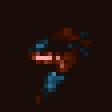

In [7]:
using VisionHeatmaps

heatmap(attr)

By default, to support batched attributions, a vector of heatmaps is returned.
Since the following examples don't use batches, we will use the `only` function to unpack singleton heatmaps:

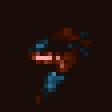

In [8]:
heatmap(attr) |> only

If we are only interested in the heatmap, we can combine analysis and heatmapping
into a single function call:

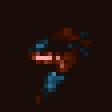

In [9]:
heatmap(input, analyzer) |> only

## Output selection
By passing an additional index to our call to `analyze`,
we can compute a feature attribution with respect to a specific output index.
Let's see why the output wasn't interpreted as a 4 (output at index 5)

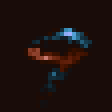

In [10]:
attr = analyze(input, analyzer, 5)
heatmap(attr) |> only

This heatmap shows us that the "upper loop" of the hand-drawn 9 has negative relevance
with respect to the output corresponding to digit 4!

The output index can also be specified when calling `heatmap`:

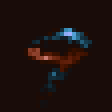

In [11]:
heatmap(input, analyzer, 5) |> only

## Analyzing batches
Feature attributions can also be computed for input batches:

In [12]:
batchsize = 20
xs, _ = MNIST(Float32, :test)[1:batchsize]
batch = reshape(xs, 28, 28, 1, :) # reshape to WHCN format
attr = analyze(batch, analyzer);

This will return a single `Attribution` `attr` for the entire batch.
Calling `heatmap` on `attr` will detect the batch dimension and return a vector of heatmaps.

,,,,,,,,,,,,,,,,,,,

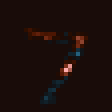
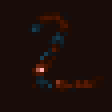
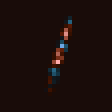
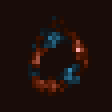
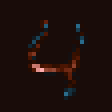
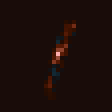
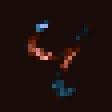
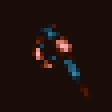
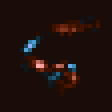
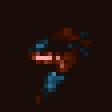
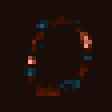
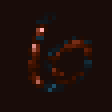
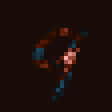
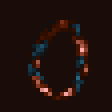
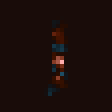
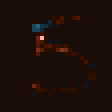
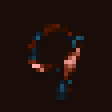
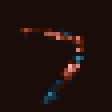
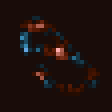
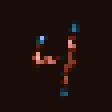

In [13]:
heatmap(attr)

## Heatmapping presets
The function `heatmap` automatically picks a preset based on the pooling of the attribution.
Since `LRP` relevances are signed and pooled by summation,
previous heatmaps were shown in a diverging blue-black-red color scheme.
Methods based on input sensitivities like `SmoothGrad` are pooled by their norm.
The resulting non-negative values are shown in a sequential color scheme:

Sampling SmoothGrad... 100%|█████████████████████████████| Time: 0:00:04


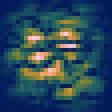

In [14]:
analyzer = SmoothGrad(model)
heatmap(input, analyzer) |> only

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*